# Galactic coordinates of each observation
#### *Open Tools, Open Sky: Doing LSST Science with Public Rubin Data & LINCC Frameworks, UdeA, Medellín, October 2026*

We convert the equatorial coordinates (RA, Dec) of every observation in `data/obs_sbn_X05_full_mpc_desig.parquet` to Galactic coordinates (longitude $l$, latitude $b$) using **spiceypy**.

**Method.** SPICE has the `GALACTIC` frame built in (System II, defined from FK4 B1950). `spiceypy.pxform('J2000', 'GALACTIC', et)` returns the $3\times3$ rotation matrix from J2000 equatorial to Galactic. Both frames are inertial, so the matrix does not depend on time and no kernels are needed. For each observation:

1. RA, Dec → unit vector: $\hat{u} = (\cos\delta\cos\alpha,\ \cos\delta\sin\alpha,\ \sin\delta)$ (`spiceypy.radrec`)
2. Rotate: $\hat{u}_{gal} = M\,\hat{u}$ (`spiceypy.mxv`)
3. Unit vector → $l, b$ (`spiceypy.recrad`)

To handle ~8M rows quickly, we take $M$ from SPICE once and apply steps 1–3 with numpy, one row group at a time. Then we check a sample against the per-row spiceypy calls and against astropy.

**Note on frames.** The MPC/ADES positions are ICRF. SPICE treats `J2000` as the same as ICRF, ignoring the ~20 mas frame bias. The result matches astropy's `FK5 → Galactic` to about 1 µas, and astropy's `ICRS → Galactic` to < 0.1″, which is far below the astrometric errors.

**Output.** `data/obs_galactic_coords.parquet` keeps the identifiers (`obsid`, `provid`, `mpc_designation`, `obstime`), the observed `ra`, `dec`, and both versions: astrometric Galactic coordinates (`gal_lon`, `gal_lat`), and coordinates corrected for stellar aberration (`ra_aberr`, `dec_aberr`, `gal_lon_aberr`, `gal_lat_aberr`). At the end, we check against JPL Horizons for (162) Laurentia.

In [17]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spiceypy
import pyarrow as pa
import pyarrow.parquet as pq

data_dir = 'data/'
obs_path = data_dir + 'obs_sbn_X05_full_mpc_desig.parquet'
out_path = data_dir + 'obs_galactic_coords.parquet'

# Columns kept in the output, to identify each observation
id_cols = ['obsid', 'provid', 'mpc_designation', 'obstime']

## Rotation matrix J2000 → Galactic

`et = 0` is arbitrary: the rotation between two inertial frames is constant.

In [18]:
M_J2000_TO_GAL = np.array(spiceypy.pxform('J2000', 'GALACTIC', 0.0))
print(M_J2000_TO_GAL)

# Sanity checks: the North Galactic Pole and the Galactic Center
# NGP (J2000):  RA = 192.85948°, Dec = +27.12825°  -> b = +90°
# GC  (J2000):  RA = 266.40500°, Dec = -28.93617°  -> l = 0°, b = 0°
for name, ra, dec in [('NGP', 192.85948, 27.12825), ('GC', 266.40500, -28.93617)]:
    _, lon, lat = spiceypy.recrad(spiceypy.mxv(M_J2000_TO_GAL, spiceypy.radrec(1.0, np.radians(ra), np.radians(dec))))
    print(f'{name}: l = {np.degrees(lon):9.5f} deg, b = {np.degrees(lat):9.5f} deg')

[[-0.05487554 -0.8734371  -0.48383499]
 [ 0.49410945 -0.44482959  0.74698225]
 [-0.86766614 -0.19807639  0.45598379]]
NGP: l = 260.65244 deg, b =  90.00000 deg
GC: l =   0.00000 deg, b =  -0.00000 deg


## Conversion functions

- `radec_to_galactic_spice`: one observation, entirely with spiceypy calls (the reference).
- `radec_to_galactic`: many observations at once, with the SPICE matrix applied in numpy.

In [19]:
def radec_to_galactic_spice(ra_deg, dec_deg, M=M_J2000_TO_GAL):
    # One observation with spiceypy: radrec -> mxv -> recrad. Returns (l, b) in degrees, l in [0, 360)
    vec = spiceypy.radrec(1.0, np.radians(ra_deg), np.radians(dec_deg))
    _, lon, lat = spiceypy.recrad(spiceypy.mxv(M, vec))
    return np.degrees(lon), np.degrees(lat)


def radec_to_galactic(ra_deg, dec_deg, M=M_J2000_TO_GAL):
    # Vectorized version: same math as radrec/mxv/recrad, on arrays. Returns (l, b) in degrees
    ra = np.radians(np.asarray(ra_deg, dtype=float))
    dec = np.radians(np.asarray(dec_deg, dtype=float))
    u = np.stack([np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)], axis=-1)
    g = u @ M.T
    lon = np.degrees(np.arctan2(g[..., 1], g[..., 0])) % 360.0
    lon = np.where(lon >= 360.0, lon - 360.0, lon)   # x % 360 can round to exactly 360 for tiny negative x
    lat = np.degrees(np.arcsin(np.clip(g[..., 2], -1.0, 1.0)))
    return lon, lat

## Check on a sample

RA and Dec are stored as text in the parquet file, so we cast them to float.

In [20]:
pf = pq.ParquetFile(obs_path)
print(f'{pf.metadata.num_rows:,} observations in {pf.metadata.num_row_groups} row groups')

sample = pf.read_row_group(0, columns=id_cols + ['ra', 'dec']).to_pandas().sample(2000, random_state=1)
sample_ra = pd.to_numeric(sample['ra'], errors='coerce').to_numpy()
sample_dec = pd.to_numeric(sample['dec'], errors='coerce').to_numpy()

l_vec, b_vec = radec_to_galactic(sample_ra, sample_dec)
l_spice, b_spice = np.array([radec_to_galactic_spice(r, d) for r, d in zip(sample_ra, sample_dec)]).T


def dlon_arcsec(l1, l2):
    # Longitude difference in arcsec, handling the 0/360 wrap
    return np.abs((l1 - l2 + 180.0) % 360.0 - 180.0) * 3600


print('vectorized vs per-row spiceypy:  max |dl| = %.2e", max |db| = %.2e"'
      % (dlon_arcsec(l_vec, l_spice).max(), (np.abs(b_vec - b_spice) * 3600).max()))

8,084,389 observations in 8 row groups
vectorized vs per-row spiceypy:  max |dl| = 2.05e-10", max |db| = 1.53e-10"


In [21]:
# Independent check with astropy
from astropy.coordinates import SkyCoord
import astropy.units as u

for frame in ['fk5', 'icrs']:
    gal = SkyCoord(sample_ra * u.deg, sample_dec * u.deg, frame=frame).galactic
    print(f'SPICE vs astropy {frame:>4} -> galactic:  max |dl cos b| = %.2e", max |db| = %.2e"'
          % ((dlon_arcsec(l_vec, gal.l.deg) * np.cos(np.radians(b_vec))).max(),
             (np.abs(b_vec - gal.b.deg) * 3600).max()))

SPICE vs astropy  fk5 -> galactic:  max |dl cos b| = 9.02e-07", max |db| = 1.04e-06"
SPICE vs astropy icrs -> galactic:  max |dl cos b| = 3.06e-02", max |db| = 1.15e-02"


## Stellar aberration

The RA/Dec reported to the MPC are **astrometric**: they give the direction of the asteroid when its light left it (light time included), but **without stellar aberration**. Aberration is the apparent shift of a source toward the direction of the observer's velocity $\vec{v}$. Its size is $\sin\phi = |\hat{u}\times\vec{v}|/c$, up to ~20.5″ from the Earth's orbital motion plus ~0.3″ from its rotation. The **apparent** direction is what a telescope actually points to. JPL Horizons, for example, gives apparent Galactic coordinates.

We compute both versions for every observation:

- `gal_lon`, `gal_lat`: astrometric (no aberration)
- `ra_aberr`, `dec_aberr`, `gal_lon_aberr`, `gal_lat_aberr`: with stellar aberration (apparent direction, in J2000/ICRF axes)

**Observer velocity.** All observations are from the Rubin Observatory (MPC `X05`). The observer velocity is the Earth's velocity relative to the Solar System barycenter, from DE440 (`spiceypy.spkezr`), plus the rotation velocity of the site. The rotation velocity is $\omega R_\oplus\cos\phi$ toward the east, and its direction comes from the local sidereal time. This simple model, ignoring precession and polar motion, is accurate to well below 1 mas.

**Aberration.** `spiceypy.stelab(pobj, vobs)` rotates the direction $\hat{u}$ by the angle $\phi$ toward $\vec{v}$, about the axis $\hat{u}\times\vec{v}$. For ~8M rows we compute the velocity with spiceypy once per distinct observation time (~48k), and apply the same rotation as `stelab` with numpy. We check it against `spiceypy.stelab` on a sample.

In [22]:
# Leap seconds (UTC -> ET) and the planetary ephemeris (Earth velocity)
spiceypy.furnsh('kernels/naif0012.tls')
spiceypy.furnsh('kernels/de440s.bsp')
C_KM_S = spiceypy.clight()           # km/s

# Rubin Observatory (MPC X05)
SITE_LON = np.radians(-70.749417)    # east longitude
SITE_LAT = np.radians(-30.244639)
R_EARTH = 6378.137                   # km
OMEGA_EARTH = 7.2921150e-5           # rad/s


def utc_to_et(times):
    # pandas timestamps (UTC) -> SPICE ephemeris time [s past J2000 TDB]
    return np.array([spiceypy.str2et(t.strftime('%Y-%m-%d %H:%M:%S.%f UTC')) for t in times])


def observer_velocity(et, jd_utc):
    # Barycentric velocity of the Rubin site, J2000 [km/s]
    v_earth = np.array(spiceypy.spkezr('EARTH', et, 'J2000', 'NONE', 'SSB')[0][3:])
    lst = np.radians(280.46061837 + 360.98564736629 * (jd_utc - 2451545.0)) + SITE_LON   # local sidereal time
    v_rot = OMEGA_EARTH * R_EARTH * np.cos(SITE_LAT) * np.array([-np.sin(lst), np.cos(lst), 0.0])
    return v_earth + v_rot


def observer_velocities(obstimes):
    # Observer velocity for each row, computed once per distinct time. Returns array (n, 3) [km/s]
    unique_times, inverse = np.unique(np.asarray(obstimes, dtype='datetime64[us]'), return_inverse=True)
    unique_times = pd.to_datetime(unique_times)
    et = utc_to_et(unique_times)
    jd = unique_times.to_julian_date().to_numpy()
    v = np.array([observer_velocity(e, j) for e, j in zip(et, jd)])
    return v[inverse]


def apparent_radec_spice(ra_deg, dec_deg, v_obs):
    # One observation with spiceypy.stelab. Returns apparent (RA, Dec) in degrees
    p_app = spiceypy.stelab(spiceypy.radrec(1.0, np.radians(ra_deg), np.radians(dec_deg)), v_obs)
    _, ra_app, dec_app = spiceypy.recrad(p_app)
    return np.degrees(ra_app), np.degrees(dec_app)


def apparent_radec(ra_deg, dec_deg, v_obs):
    # Vectorized stelab: rotate u by phi = asin(|u x v/c|) about u x v. Returns apparent (RA, Dec) in degrees
    ra = np.radians(np.asarray(ra_deg, dtype=float))
    dec = np.radians(np.asarray(dec_deg, dtype=float))
    u = np.stack([np.cos(dec) * np.cos(ra), np.cos(dec) * np.sin(ra), np.sin(dec)], axis=-1)
    h = np.cross(u, np.asarray(v_obs) / C_KM_S)
    sin_phi = np.linalg.norm(h, axis=-1, keepdims=True)
    cos_phi = np.sqrt(1.0 - sin_phi**2)
    h_unit = np.divide(h, sin_phi, out=np.zeros_like(h), where=sin_phi > 0)
    u_app = u * cos_phi + np.cross(h_unit, u) * sin_phi   # Rodrigues rotation (h is perpendicular to u)
    ra_app = np.degrees(np.arctan2(u_app[:, 1], u_app[:, 0])) % 360.0
    ra_app = np.where(ra_app >= 360.0, ra_app - 360.0, ra_app)
    dec_app = np.degrees(np.arcsin(np.clip(u_app[:, 2], -1.0, 1.0)))
    return ra_app, dec_app

In [23]:
# Check the vectorized version against spiceypy.stelab on the sample
v_sample = observer_velocities(sample['obstime'])
ra_app_vec, dec_app_vec = apparent_radec(sample_ra, sample_dec, v_sample)
ra_app_spice, dec_app_spice = np.array([apparent_radec_spice(r, d, v)
                                        for r, d, v in zip(sample_ra, sample_dec, v_sample)]).T

shift = np.hypot(dlon_arcsec(ra_app_vec, sample_ra) * np.cos(np.radians(sample_dec)),
                 (dec_app_vec - sample_dec) * 3600)    # total aberration shift [arcsec]
print('aberration shift in the sample: %.2f" to %.2f"' % (shift.min(), shift.max()))
print('vectorized vs spiceypy.stelab:  max |dRA cos Dec| = %.2e", max |dDec| = %.2e"'
      % ((dlon_arcsec(ra_app_vec, ra_app_spice) * np.cos(np.radians(dec_app_vec))).max(),
         (np.abs(dec_app_vec - dec_app_spice) * 3600).max()))

aberration shift in the sample: 2.89" to 20.99"
vectorized vs spiceypy.stelab:  max |dRA cos Dec| = 2.05e-10", max |dDec| = 5.12e-11"


## All observations

We read one row group at a time (only the columns we need), compute both versions of the coordinates, and write the result to `data/obs_galactic_coords.parquet` with the same row order as the input file.

In [24]:
t0 = time.time()
writer = None
n_bad = 0
for i in range(pf.metadata.num_row_groups):
    chunk = pf.read_row_group(i, columns=id_cols + ['ra', 'dec']).to_pandas()
    chunk['ra'] = pd.to_numeric(chunk['ra'], errors='coerce')
    chunk['dec'] = pd.to_numeric(chunk['dec'], errors='coerce')
    n_bad += int((chunk['ra'].isna() | chunk['dec'].isna()).sum())

    # Astrometric (no aberration)
    chunk['gal_lon'], chunk['gal_lat'] = radec_to_galactic(chunk['ra'].to_numpy(), chunk['dec'].to_numpy())

    # With stellar aberration
    v_obs = observer_velocities(chunk['obstime'])
    chunk['ra_aberr'], chunk['dec_aberr'] = apparent_radec(chunk['ra'].to_numpy(), chunk['dec'].to_numpy(), v_obs)
    chunk['gal_lon_aberr'], chunk['gal_lat_aberr'] = radec_to_galactic(chunk['ra_aberr'].to_numpy(),
                                                                      chunk['dec_aberr'].to_numpy())

    table = pa.Table.from_pandas(chunk, preserve_index=False)
    if writer is None:
        writer = pq.ParquetWriter(out_path, table.schema)
    writer.write_table(table)
    print(f'row group {i + 1}/{pf.metadata.num_row_groups}: {len(chunk):,} rows  ({time.time() - t0:.1f} s)')
writer.close()
print(f'Saved {out_path}  ({n_bad} rows without valid RA/Dec -> NaN)')

row group 1/8: 1,048,576 rows  (3.3 s)
row group 2/8: 1,048,576 rows  (7.1 s)
row group 3/8: 1,048,576 rows  (10.2 s)
row group 4/8: 1,048,576 rows  (13.7 s)
row group 5/8: 1,048,576 rows  (17.1 s)
row group 6/8: 1,048,576 rows  (20.6 s)
row group 7/8: 1,048,576 rows  (24.1 s)
row group 8/8: 744,357 rows  (26.9 s)
Saved data/obs_galactic_coords.parquet  (0 rows without valid RA/Dec -> NaN)


## Look at the result

Galactic latitude of the observations, and the sky density in Galactic coordinates. Asteroids stay near the ecliptic, which in Galactic coordinates is a wide S-shaped band crossing the Galactic plane near the Galactic center and anticenter.

In [25]:
gal = pq.read_table(out_path, columns=['gal_lon', 'gal_lat', 'gal_lon_aberr', 'gal_lat_aberr']).to_pandas()

# Size of the aberration correction in Galactic coordinates [arcsec]
gal['dl_cosb_aberr [arcsec]'] = ((gal['gal_lon_aberr'] - gal['gal_lon'] + 180) % 360 - 180) * 3600 \
    * np.cos(np.radians(gal['gal_lat']))
gal['db_aberr [arcsec]'] = (gal['gal_lat_aberr'] - gal['gal_lat']) * 3600
gal.describe()

,gal_lon,gal_lat,gal_lon_aberr,gal_lat_aberr,dl_cosb_aberr [arcsec],db_aberr [arcsec]
count,8.084389e+06,8.084389e+06,8.084389e+06,8.084389e+06,8.084389e+06,8.084389e+06
mean,1.364797e+02,-3.583763e+00,1.364796e+02,-3.586359e+00,1.169001e+01,-9.343814e+00
std,1.306730e+02,4.488886e+01,1.306726e+02,4.488950e+01,4.198692e+00,7.321405e+00
min,1.624612e-05,-7.999140e+01,5.939529e-06,-7.999414e+01,-1.873452e+01,-1.906171e+01
25%,2.706243e+01,-4.268500e+01,2.706448e+01,-4.268827e+01,9.236675e+00,-1.509908e+01
50%,6.088373e+01,-1.578739e+01,6.088661e+01,-1.579161e+01,1.132867e+01,-1.205680e+01
75%,2.839317e+02,4.214960e+01,2.839433e+02,4.215078e+01,1.459745e+01,-3.360476e+00
max,3.600000e+02,7.239668e+01,3.600000e+02,7.239662e+01,2.082675e+01,2.081726e+01


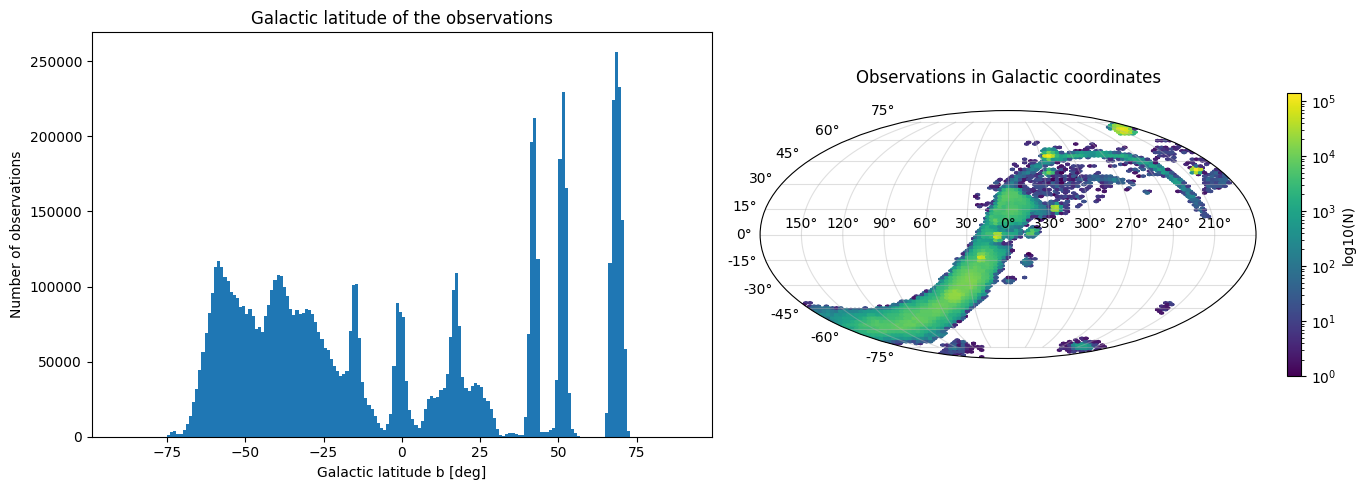

In [33]:
fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1)
ax1.hist(gal['gal_lat'].dropna(), bins=180, range=(-90, 90), color='tab:blue')
ax1.set_xlabel('Galactic latitude b [deg]')
ax1.set_ylabel('Number of observations')
ax1.set_title('Galactic latitude of the observations')

# Mollweide sky map, l = 0 at the center, increasing to the left (astronomical convention)
ax2 = fig.add_subplot(1, 2, 2, projection='mollweide')
lon_wrapped = -np.radians((gal['gal_lon'].to_numpy() + 180.0) % 360.0 - 180.0)
lat = np.radians(gal['gal_lat'].to_numpy())
ok = np.isfinite(lon_wrapped) & np.isfinite(lat)
h = ax2.hexbin(lon_wrapped[ok], lat[ok], gridsize=120, bins='log', cmap='viridis', mincnt=1)
ax2.set_xticks(np.radians([-150, -120, -90, -60, -30, 0, 30, 60, 90, 120, 150]))
ax2.set_xticklabels(['150°', '120°', '90°', '60°', '30°', '0°', '330°', '300°', '270°', '240°', '210°'])
ax2.grid(True, alpha=0.4)
ax2.set_title('Observations in Galactic coordinates', pad=20)
fig.colorbar(h, ax=ax2, label='log10(N)', shrink=0.7)

plt.tight_layout()
plt.savefig('figures/observations_galatic_coordinates.png')
plt.show()

## Validation with (162) Laurentia and JPL Horizons

As an independent check, we compare our Galactic coordinates of (162) Laurentia with those from **JPL Horizons**. We ask for an observer at the Rubin Observatory (MPC code `X05`) at the same times as the observations. We request quantity `1` (astrometric RA/Dec, ICRF) and quantity `33` (Galactic longitude and latitude, `GlxLon`, `GlxLat`).

Horizons computes `GlxLon/GlxLat` from the **apparent** direction, which includes stellar aberration. So we expect:

1. Astrometric `gal_lon`, `gal_lat` vs Horizons: the ~20″ aberration offset.
2. **Transformation test:** Horizons' own astrometric RA/Dec → our aberration (`apparent_radec`) → our J2000→Galactic rotation. Compared with Horizons `GlxLon/GlxLat`, this tests only our calculation.
3. **Observations:** `gal_lon_aberr`, `gal_lat_aberr` from the saved file vs Horizons. This also includes the astrometric residuals of the observations against the orbit (tens of mas).

In [27]:
from astroquery.jplhorizons import Horizons

laurentia = pq.read_table(out_path, filters=[('mpc_designation', '=', '(162) Laurentia')]).to_pandas()
laurentia = laurentia.sort_values('obstime').reset_index(drop=True)
laurentia['jd_utc'] = laurentia['obstime'].map(lambda t: t.to_julian_date())
print(len(laurentia), 'observations of (162) Laurentia')

# Horizons observer ephemeris from Rubin (X05). Epochs in JD UTC
hor = Horizons(id='162', id_type='smallbody', location='X05',
               epochs=laurentia['jd_utc'].tolist()).ephemerides(quantities='1,33', extra_precision=True).to_pandas()
hor = hor.sort_values('datetime_jd').reset_index(drop=True)    # same order as laurentia
assert np.allclose(hor['datetime_jd'], laurentia['jd_utc'], atol=1e-7)
hor[['datetime_str', 'RA', 'DEC', 'GlxLon', 'GlxLat']]

12 observations of (162) Laurentia


,datetime_str,RA,DEC,GlxLon,GlxLat
0,2025-Sep-03 08:46:25.045,355.760400,-8.501713,78.786408,-65.329538
1,2025-Sep-03 08:47:04.756,355.760317,-8.501745,78.786206,-65.329511
2,2025-Sep-03 08:49:04.411,355.760064,-8.501841,78.785595,-65.329428
3,2025-Sep-03 08:49:44.106,355.759980,-8.501872,78.785393,-65.329401
4,2025-Sep-03 08:51:43.757,355.759728,-8.501968,78.784782,-65.329319
5,2025-Sep-03 08:55:02.808,355.759308,-8.502127,78.783767,-65.329182
6,2025-Sep-03 08:57:42.368,355.758972,-8.502254,78.782953,-65.329072
7,2025-Nov-17 02:10:12.787,346.815920,-10.111583,62.687457,-60.142416
8,2025-Nov-17 03:46:59.261,346.817619,-10.108342,62.694603,-60.141702
9,2025-Nov-17 03:50:33.350,346.817683,-10.108223,62.694870,-60.141677


In [28]:
# Galactic coordinates of (162) Laurentia: ours (astrometric), ours with aberration, and JPL Horizons [deg]
laurentia_lb = pd.DataFrame({
    'obstime (UTC)': laurentia['obstime'].dt.strftime('%Y-%m-%d %H:%M:%S'),
    'l ours [deg]': laurentia['gal_lon'],
    'l ours + aberration [deg]': laurentia['gal_lon_aberr'],
    'l JPL [deg]': hor['GlxLon'],
    'b ours [deg]': laurentia['gal_lat'],
    'b ours + aberration [deg]': laurentia['gal_lat_aberr'],
    'b JPL [deg]': hor['GlxLat'],
})
laurentia_lb.style.format(precision=6)

,obstime (UTC),l ours [deg],l ours + aberration [deg],l JPL [deg],b ours [deg],b ours + aberration [deg],b JPL [deg]
0,2025-09-03 08:46:25,78.773463,78.786411,78.786408,-65.328150,-65.329538,-65.329538
1,2025-09-03 08:47:04,78.773258,78.786206,78.786206,-65.328122,-65.329510,-65.329511
2,2025-09-03 08:49:04,78.772678,78.785625,78.785595,-65.328046,-65.329434,-65.329428
3,2025-09-03 08:49:44,78.772461,78.785408,78.785393,-65.328016,-65.329403,-65.329401
4,2025-09-03 08:51:43,78.771820,78.784766,78.784782,-65.327931,-65.329319,-65.329319
5,2025-09-03 08:55:02,78.770836,78.783780,78.783767,-65.327799,-65.329187,-65.329182
6,2025-09-03 08:57:42,78.770019,78.782962,78.782953,-65.327687,-65.329074,-65.329072
7,2025-11-17 02:10:12,62.684535,62.687463,62.687457,-60.141134,-60.142421,-60.142416
8,2025-11-17 03:46:59,62.691723,62.694606,62.694603,-60.140439,-60.141708,-60.141702
9,2025-11-17 03:50:33,62.691983,62.694865,62.694870,-60.140410,-60.141678,-60.141677


In [29]:
def compare(l1, b1, l2, b2):
    # Differences in arcsec: dl * cos(b) (true angle on the sky) and db
    dl = (np.asarray(l1) - np.asarray(l2) + 180.0) % 360.0 - 180.0
    return dl * np.cos(np.radians(np.asarray(b2))) * 3600, (np.asarray(b1) - np.asarray(b2)) * 3600


# 1. Astrometric vs Horizons
dl_direct, db_direct = compare(laurentia['gal_lon'], laurentia['gal_lat'], hor['GlxLon'], hor['GlxLat'])

# 2. Transformation test: Horizons astrometric RA/Dec through our aberration + rotation
v_laurentia = observer_velocities(laurentia['obstime'])
ra_hor_app, dec_hor_app = apparent_radec(hor['RA'].to_numpy(), hor['DEC'].to_numpy(), v_laurentia)
l_hor_pipe, b_hor_pipe = radec_to_galactic(ra_hor_app, dec_hor_app)
dl_pipe, db_pipe = compare(l_hor_pipe, b_hor_pipe, hor['GlxLon'], hor['GlxLat'])

# 3. Observations with aberration (saved columns) vs Horizons
dl_obs, db_obs = compare(laurentia['gal_lon_aberr'], laurentia['gal_lat_aberr'], hor['GlxLon'], hor['GlxLat'])

# For reference: observed vs Horizons astrometric RA/Dec (astrometric residuals)
dra_obs, ddec_obs = compare(laurentia['ra'], laurentia['dec'], hor['RA'], hor['DEC'])

laurentia_validation = pd.DataFrame({
    'obstime (UTC)': laurentia['obstime'].dt.strftime('%Y-%m-%d %H:%M:%S'),
    'no aberr: dl cos b ["]': dl_direct, 'no aberr: db ["]': db_direct,
    'Horizons RA/Dec: dl cos b ["]': dl_pipe, 'Horizons RA/Dec: db ["]': db_pipe,
    'observed: dl cos b ["]': dl_obs, 'observed: db ["]': db_obs,
    'observed - Horizons: dRA cos Dec ["]': dra_obs, 'observed - Horizons: dDec ["]': ddec_obs,
})
laurentia_validation

,obstime (UTC),"no aberr: dl cos b [""]","no aberr: db [""]","Horizons RA/Dec: dl cos b [""]","Horizons RA/Dec: db [""]","observed: dl cos b [""]","observed: db [""]","observed - Horizons: dRA cos Dec [""]","observed - Horizons: dDec [""]"
0,2025-09-03 08:46:25,-19.451937,4.997911,-0.000534,0.000792,0.004664,0.000955,0.003949,0.003384
1,2025-09-03 08:47:04,-19.455857,5.000234,-0.001495,0.001891,0.000246,0.003499,0.000349,0.002344
2,2025-09-03 08:49:04,-19.409541,4.975956,-0.000780,-0.000757,0.045067,-0.020095,0.047845,0.013666
3,2025-09-03 08:49:44,-19.432152,4.986855,-0.001561,0.000274,0.021952,-0.008974,0.024118,0.007531
4,2025-09-03 08:51:43,-19.476888,4.995567,-0.000638,0.001134,-0.024302,0.000418,-0.017991,-0.015390
5,2025-09-03 08:55:02,-19.430388,4.977393,-0.001001,0.000312,0.019661,-0.016576,0.026685,-0.000209
6,2025-09-03 08:57:42,-19.434744,4.984638,-0.000460,-0.001126,0.013249,-0.008374,0.015224,0.002945
7,2025-11-17 02:10:12,-5.236481,4.615629,-0.002405,0.003602,0.011514,-0.016745,0.024592,-0.001685
8,2025-11-17 03:46:59,-5.161970,4.547174,-0.003138,0.003120,0.006207,-0.020226,0.024111,-0.007135
9,2025-11-17 03:50:33,-5.174576,4.561863,-0.003750,0.003334,-0.009640,-0.002569,0.000982,-0.008280


In [30]:
summary = pd.DataFrame({
    'max |dl cos b| ["]': [np.abs(x).max() for x in (dl_direct, dl_pipe, dl_obs)],
    'max |db| ["]': [np.abs(x).max() for x in (db_direct, db_pipe, db_obs)],
}, index=['gal_lon/gal_lat (astrometric) vs Horizons',
          'Horizons RA/Dec + aberration + rotation vs Horizons (transformation test)',
          'gal_lon_aberr/gal_lat_aberr (observed) vs Horizons'])
print('Astrometric residuals of the observations, max |dRA cos Dec| = %.3f", max |dDec| = %.3f"'
      % (np.abs(dra_obs).max(), np.abs(ddec_obs).max()))
summary

Astrometric residuals of the observations, max |dRA cos Dec| = 0.048", max |dDec| = 0.031"


,"max |dl cos b| [""]","max |db| [""]"
gal_lon/gal_lat (astrometric) vs Horizons,19.476888,5.000234
Horizons RA/Dec + aberration + rotation vs Horizons (transformation test),0.004458,0.003602
gal_lon_aberr/gal_lat_aberr (observed) vs Horizons,0.045067,0.020226


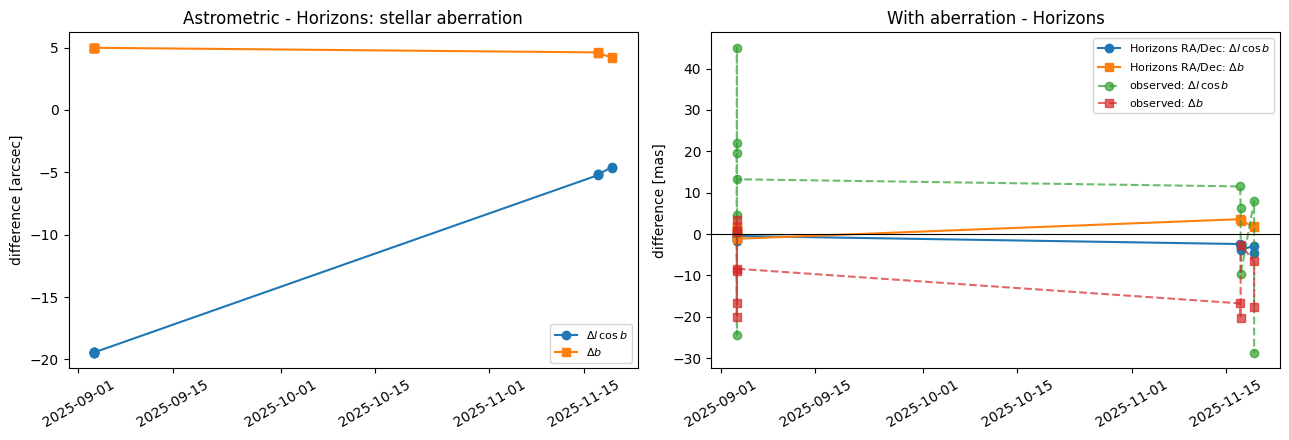

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = laurentia['obstime']

axes[0].plot(x, dl_direct, 'o-', label=r'$\Delta l\,\cos b$')
axes[0].plot(x, db_direct, 's-', label=r'$\Delta b$')
axes[0].set_title('Astrometric - Horizons: stellar aberration')
axes[0].set_ylabel('difference [arcsec]')

axes[1].plot(x, dl_pipe * 1e3, 'o-', label=r'Horizons RA/Dec: $\Delta l\,\cos b$')
axes[1].plot(x, db_pipe * 1e3, 's-', label=r'Horizons RA/Dec: $\Delta b$')
axes[1].plot(x, dl_obs * 1e3, 'o--', alpha=0.7, label=r'observed: $\Delta l\,\cos b$')
axes[1].plot(x, db_obs * 1e3, 's--', alpha=0.7, label=r'observed: $\Delta b$')
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('With aberration - Horizons')
axes[1].set_ylabel('difference [mas]')

for ax in axes:
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Result.** Without aberration, our $l, b$ differ from Horizons by ~20″, which is the stellar aberration (Horizons gives apparent Galactic coordinates). With aberration, Horizons' own RA/Dec passed through our calculation reproduce Horizons `GlxLon/GlxLat` to a few milliarcseconds. So both the aberration correction and the rotation from `spiceypy.pxform('J2000', 'GALACTIC', et)` are correct. The saved `gal_lon_aberr`, `gal_lat_aberr` of the observations agree with Horizons to within a few tens of mas, the same size as their astrometric residuals against the orbit.

Which columns to use: `gal_lon`, `gal_lat` (astrometric) for catalogues and for comparing positions across epochs; `gal_lon_aberr`, `gal_lat_aberr` for the apparent direction as seen by the observer, as Horizons gives it.

In [34]:
laurentia

,obsid,provid,mpc_designation,obstime,ra,dec,gal_lon,gal_lat,ra_aberr,dec_aberr,gal_lon_aberr,gal_lat_aberr,jd_utc
0,Lw02bPBT0000CADL01000000G,A876 HB,(162) Laurentia,2025-09-03 08:46:25.045,355.760402,-8.501713,78.773463,-65.328150,355.765539,-8.499406,78.786411,-65.329538,2.460922e+06
1,Lw02bPBT0000CADL01000000N,A876 HB,(162) Laurentia,2025-09-03 08:47:04.756,355.760317,-8.501744,78.773258,-65.328122,355.765454,-8.499438,78.786206,-65.329510,2.460922e+06
2,Lw02bPBT0000CADL01000000O,A876 HB,(162) Laurentia,2025-09-03 08:49:04.411,355.760078,-8.501837,78.772678,-65.328046,355.765215,-8.499531,78.785625,-65.329434,2.460922e+06
3,Lw02bPBT0000CADL01000000L,A876 HB,(162) Laurentia,2025-09-03 08:49:44.106,355.759987,-8.501870,78.772461,-65.328016,355.765124,-8.499564,78.785408,-65.329403,2.460922e+06
4,Lw02bPBT0000CADL01000000H,A876 HB,(162) Laurentia,2025-09-03 08:51:43.757,355.759723,-8.501972,78.771820,-65.327931,355.764859,-8.499666,78.784766,-65.329319,2.460922e+06
5,Lw02bPBT0000CADL01000000I,A876 HB,(162) Laurentia,2025-09-03 08:55:02.808,355.759316,-8.502127,78.770836,-65.327799,355.764451,-8.499821,78.783780,-65.329187,2.460922e+06
6,Lw02bPBT0000CADL01000000M,A876 HB,(162) Laurentia,2025-09-03 08:57:42.368,355.758976,-8.502253,78.770019,-65.327687,355.764111,-8.499947,78.782962,-65.329074,2.460922e+06
7,Lw02bPBT0000CADL01000000D,A876 HB,(162) Laurentia,2025-11-17 02:10:12.787,346.815927,-10.111584,62.684535,-60.141134,346.817870,-10.111237,62.687463,-60.142421,2.460997e+06
8,Lw02bPBT0000CADL01000000J,A876 HB,(162) Laurentia,2025-11-17 03:46:59.261,346.817625,-10.108344,62.691723,-60.140439,346.819541,-10.108004,62.694606,-60.141708,2.460997e+06
9,Lw02bPBT0000CADL01000000K,A876 HB,(162) Laurentia,2025-11-17 03:50:33.350,346.817684,-10.108225,62.691983,-60.140410,346.819598,-10.107885,62.694865,-60.141678,2.460997e+06
